#### Import Libraries

In [1]:
# Import libraries
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from factor_analyzer import Rotator
from sklearn.metrics import silhouette_score
import geopandas as gpd
from sklearn_extra.cluster import CLARA
from sklearn.cluster import MiniBatchKMeans
from sqlalchemy import text, create_engine
from PIL import Image

#### Create the connection with the DB (optional)
##### Import Data

In [37]:
# Create the connection with the DB
engine = create_engine("postgresql://urbaninfo:@cirrus.ita.chalmers.se/emc2_15mc")
conn = engine.connect()

In [6]:
# Create a new schema when it is necessary
conn.execute(text('''CREATE SCHEMA IF NOT EXISTS s8_paper_multiscalar_foreground_network'''))
conn.commit()

In [5]:
# Import data
# GOT_nms
got_nms_query = text('SELECT * FROM s7_paper_foreground_street_networks."1_segment_analysis_nms_gothenburg"')
got_nms = gpd.read_postgis(got_nms_query, engine, geom_col='geometry')

# VER_nms
ver_nms_query = text('''SELECT * FROM s7_paper_foreground_street_networks."1_segment_analysis_nms_versilia"''')
ver_nms = gpd.read_postgis(ver_nms_query, engine, geom_col='geometry')

# NIC_nms
nic_nms_query = text('''SELECT * FROM s3_segment_analysis_france."s3_segment_analysis_nms_complete_nice_v2"''')
nic_nms = gpd.read_postgis(nic_nms_query, engine, geom_col='geometry')

# LIl_nms
lil_nms_query = text('''SELECT * FROM s3_segment_analysis_france."s3_segment_analysis_nms_complete_lille_v2"''')
lil_nms = gpd.read_postgis(lil_nms_query, engine, geom_col='geometry')

# VIE_nms
vie_nms_query = text('''SELECT * FROM s7_paper_foreground_street_networks."1_segment_analysis_nms_vienna"''')
vie_nms = gpd.read_postgis(vie_nms_query, engine, geom_col='geometry')

#### Pre-process the data

In [7]:
# Function reproject the gdf:
def reproject_crs(gdf, crs):
    gdf_reprojected = gdf.to_crs(crs)

    return gdf_reprojected

# Usage:
got_nms_reprojected = reproject_crs(got_nms, 'EPSG:3857')
ver_nms_reprojected = reproject_crs(ver_nms, 'EPSG:3857')
nic_nms_reprojected = reproject_crs(nic_nms, 'EPSG:3857')
lil_nms_reprojected = reproject_crs(lil_nms, 'EPSG:3857')
vie_nms_reprojected = reproject_crs(vie_nms, 'EPSG:3857')

In [8]:
# Function separate zeros:
def separate_zeros(df):
    zero_rows = (df.iloc[:, 3:13] == 0).all(axis=1)
    df_nms_zeros = df[zero_rows]
    df_nms_nonzeros = df[~zero_rows]

    return df_nms_zeros, df_nms_nonzeros

# Usage:
got_nms_zeros_reprojected, got_nms_nonzeros_reprojected = separate_zeros(got_nms_reprojected)
ver_nms_zeros_reprojected, ver_nms_nonzeros_reprojected = separate_zeros(ver_nms_reprojected)
nic_nms_zeros_reprojected, nic_nms_nonzeros_reprojected = separate_zeros(nic_nms_reprojected)
lil_nms_zeros_reprojected, lil_nms_nonzeros_reprojected = separate_zeros(lil_nms_reprojected)
vie_nms_zeros_reprojected, vie_nms_nonzeros_reprojected = separate_zeros(vie_nms_reprojected)

#### Export the pre-processed data

In [10]:
# Function export:
def export(gdf, table_name, schema_name, engine):
    gdf.to_postgis(
        table_name,
        engine,
        schema=schema_name,
        if_exists='replace'
    )

# Usage
export(got_nms_zeros_reprojected, '1_segment_nms_got_zeros_EPSG3857', 's8_paper_multiscalar_foreground_network', engine)
export(got_nms_nonzeros_reprojected, '1_segment_nms_got_nonzeros_EPSG3857', 's8_paper_multiscalar_foreground_network', engine)
export(ver_nms_zeros_reprojected, '1_segment_nms_ver_zeros_EPSG3857', 's8_paper_multiscalar_foreground_network', engine)
export(ver_nms_nonzeros_reprojected, '1_segment_nms_ver_nonzeros_EPSG3857', 's8_paper_multiscalar_foreground_network', engine)
export(nic_nms_zeros_reprojected, '1_segment_nms_nic_zeros_EPSG3857', 's8_paper_multiscalar_foreground_network', engine)
export(nic_nms_nonzeros_reprojected, '1_segment_nms_nic_nonzeros_EPSG3857', 's8_paper_multiscalar_foreground_network', engine)
export(lil_nms_zeros_reprojected, '1_segment_nms_lil_zeros_EPSG3857', 's8_paper_multiscalar_foreground_network', engine)
export(lil_nms_nonzeros_reprojected, '1_segment_nms_lil_nonzeros_EPSG3857', 's8_paper_multiscalar_foreground_network', engine)
export(vie_nms_zeros_reprojected, '1_segment_nms_vie_zeros_EPSG3857', 's8_paper_multiscalar_foreground_network', engine)
export(vie_nms_nonzeros_reprojected, '1_segment_nms_vie_nonzeros_EPSG3857', 's8_paper_multiscalar_foreground_network', engine)

## PCA analysis

#### Create the PCs, and test the variance

In [11]:
# Create a dictionary to concatenate the tables of the different cities
cities = {'Gothenburg': got_nms_nonzeros_reprojected, 'Versilia': ver_nms_nonzeros_reprojected,
          'Nice':nic_nms_nonzeros_reprojected, 'Lille':lil_nms_nonzeros_reprojected,
          'Vienna':vie_nms_nonzeros_reprojected}
# Display to check
print(cities)

{'Gothenburg':            fid                                           geometry      id  \
0            1  LINESTRING (1342159.842 7883580.812, 1342181.1...       1   
1            2  LINESTRING (1342169.171 7883499.833, 1342181.1...       2   
2            3  LINESTRING (1345950.739 7898301.149, 1345956.5...       3   
3            4  LINESTRING (1345947.221 7898257.083, 1345950.7...       4   
4            5  LINESTRING (1345954.679 7898196.095, 1345949.8...       5   
...        ...                                                ...     ...   
405277  406436  LINESTRING (1329698.249 7877830.647, 1329699.4...  406436   
405278  406437  LINESTRING (1329695.555 7877821.451, 1329698.2...  406437   
405279  406438  LINESTRING (1329692.95 7877815.12, 1329695.555...  406438   
405280  406439  LINESTRING (1329689.588 7877808.912, 1329692.9...  406439   
405281  406440  LINESTRING (1329687.127 7877795.773, 1329689.5...  406440   

                           uv   abw500     abw1k   abw1500  

In [12]:
# Set the dictionaries and parameters
city_pca_results = {}
explained_variance = {}
pca_loadings = {}
n_components = 3

# Set the seed number
seed_number = 3011

# Loop through each city's DataFrame to standardize and perform PCA
for city_name, data in cities.items():
    filtered_cols = [col for col in data.columns if col.startswith('abw')]
    city_data = data[filtered_cols]

    # Standardize data and perform PCA
    pca = PCA(n_components=n_components, random_state=seed_number)
    transformed_data = pca.fit_transform(StandardScaler().fit_transform(city_data))

    # Store explained variance and loadings
    explained_variance[city_name] = pca.explained_variance_ratio_
    pca_loadings[city_name] = pca.components_.T  # Store loadings (transpose for feature alignment)

    # Create a DataFrame for PCA results and store it
    city_pca_results[city_name] = pd.concat([data.reset_index(drop=True),
                                             pd.DataFrame(transformed_data,
                                                          columns=[f'PC{i + 1}' for i in range(n_components)])], axis=1)

# Create DataFrame
pca_results_combined = pd.concat(city_pca_results.values(), keys=city_pca_results.keys(), names=['city']).reset_index(level=0)

#### Plot the variance

Explained Variance Ratios by City:
Gothenburg: [0.83022837 0.13158424 0.02886812]
Versilia: [0.83890379 0.12704861 0.02543664]
Nice: [0.82050493 0.13903639 0.03065257]
Lille: [0.79790047 0.15261108 0.0371027 ]
Vienna: [0.84891464 0.11803192 0.02567733]

Total Explained Variance by City:
Gothenburg: 0.9907
Versilia: 0.9914
Nice: 0.9902
Lille: 0.9876
Vienna: 0.9926


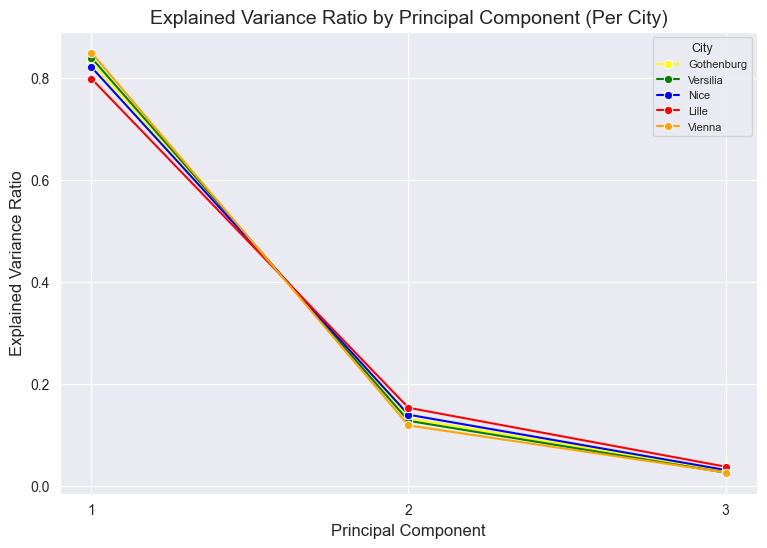

In [13]:
# Print explained variance ratios
print("Explained Variance Ratios by City:")
for city, variance in explained_variance.items():
    print(f"{city}: {variance}")

print("\nTotal Explained Variance by City:")
for city, total_variance in {city: sum(var) for city, var in explained_variance.items()}.items():
    print(f"{city}: {total_variance:.4f}")

plt.figure(figsize=(9, 6))

hue_color_map = {'Versilia': 'green', 'Gothenburg': 'yellow', 'Nice':'blue', 'Lille': 'red', 'Vienna':'orange'}

# Loop through each city to plot its explained variance
for city, variance in explained_variance.items():
    sns.lineplot(x=range(1, n_components + 1), y=variance, color=hue_color_map[city], marker='o', label=city)

# Add titles and labels, export the image
plt.title('Explained Variance Ratio by Principal Component (Per City)', fontsize=14)
plt.xlabel('Principal Component', fontsize=12)
plt.ylabel('Explained Variance Ratio', fontsize=12)
plt.xticks(ticks=range(1, n_components + 1))
plt.legend(title="City", fontsize=8, title_fontsize=9)
plt.savefig('C:/Users/monaliza/PycharmProjects/paper-multiscalar-foreground-network/0_data-visualization/1-om-variance-ratio.png.png', format='png', dpi=300, bbox_inches='tight')
plt.show()

#### Create rotated components

In [14]:
# Set the dictionary
pca_rotated = {}

# Apply varimax rotation to PCA loadings per city
for city_name, loadings in pca_loadings.items():
    rotator = Rotator(method='varimax', normalize=True)
    rotated_loadings = rotator.fit_transform(loadings)

    # Identify ABw columns from the corresponding city's DataFrame
    abw_columns = [col for col in cities[city_name].columns if col.startswith('abw')]

    # Store rotated loadings as DataFrame
    pca_rotated[city_name] = pd.DataFrame(
        rotated_loadings,
        columns=[f'RC{i + 1}' for i in range(rotated_loadings.shape[1])],
        index=abw_columns
    )

# Combine all cities' rotated components into a single DataFrame
pca_rotated_components = (
    pd.concat(pca_rotated.values(), keys=pca_rotated.keys())
    .reset_index()
    .rename(columns={'level_0': 'city', 'level_1': 'Radius'})
)

#### Plot rotated components

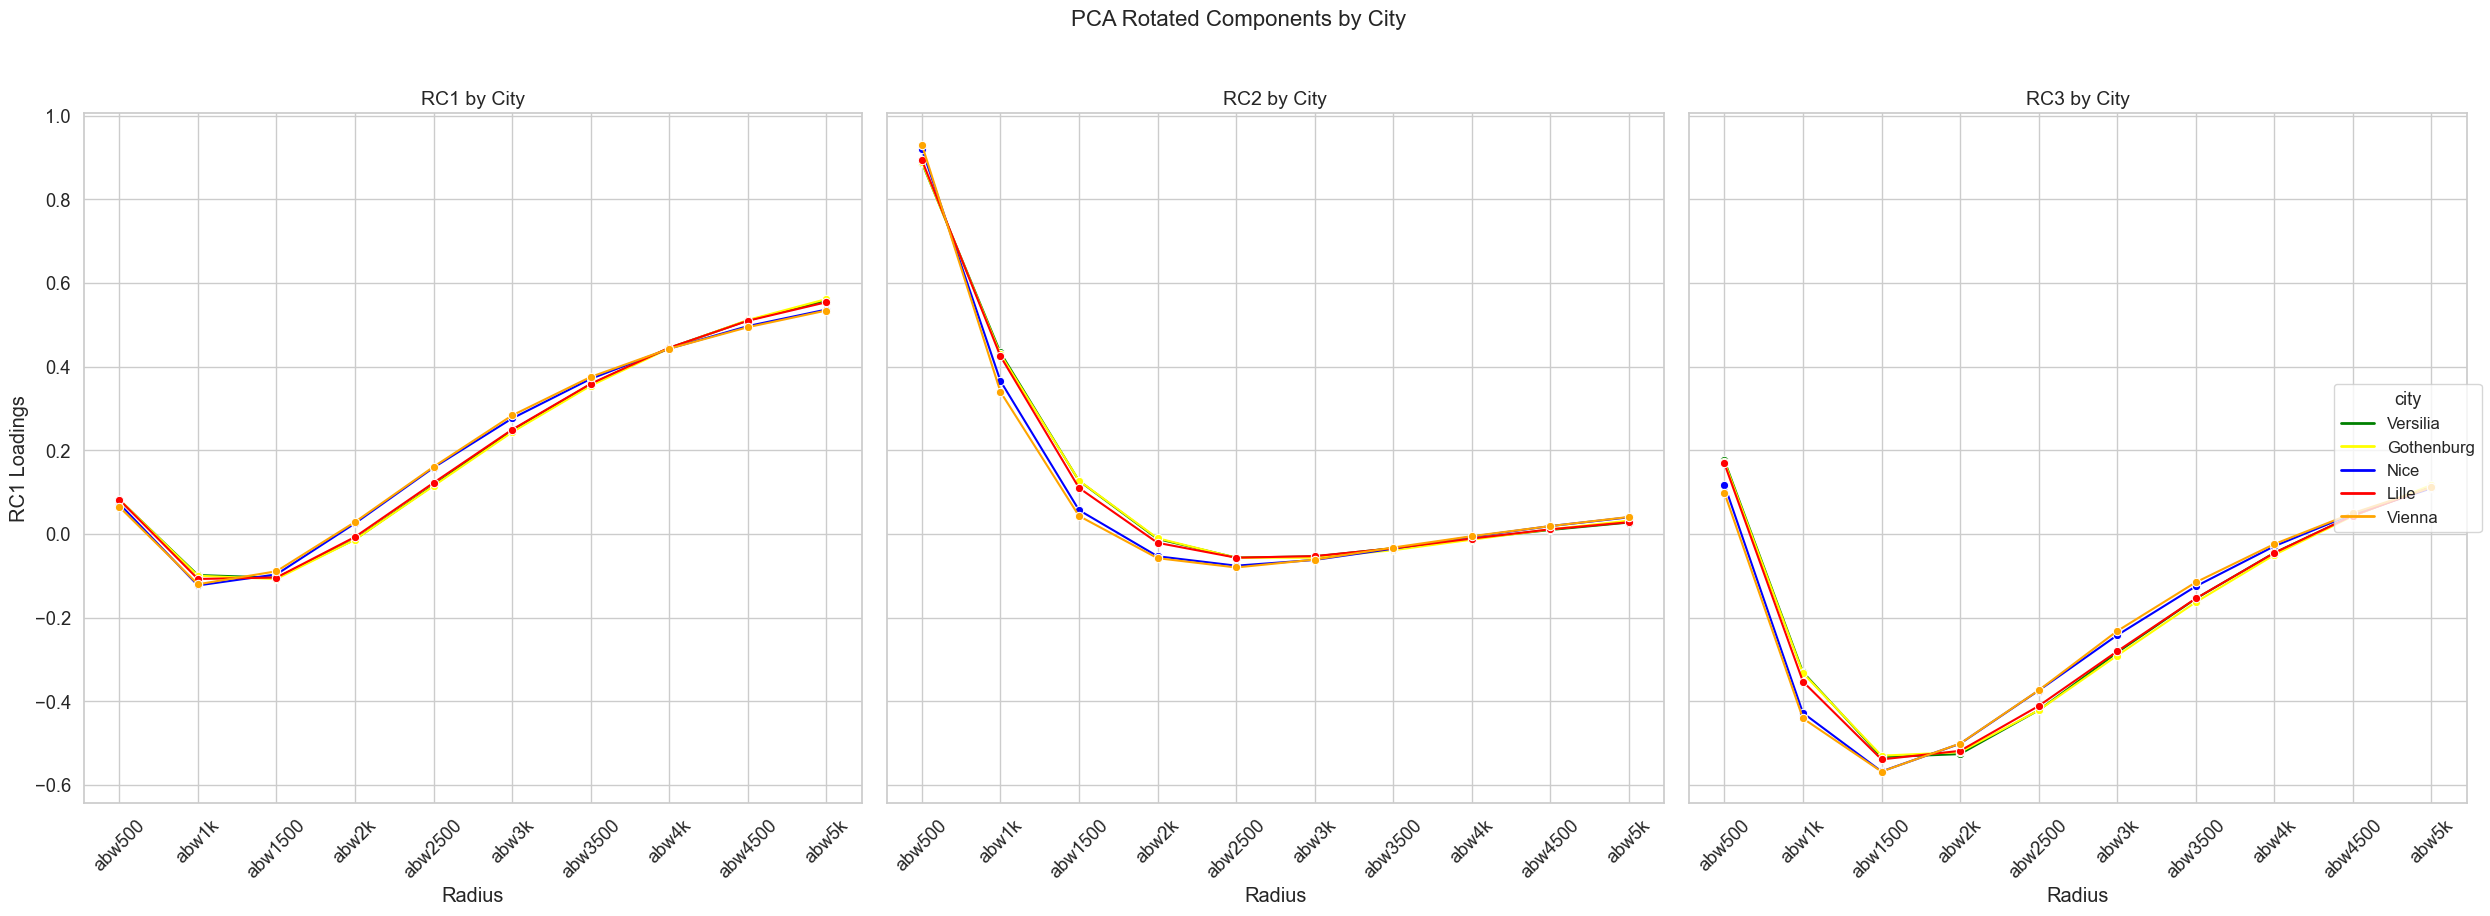

In [18]:
# Set seaborn plot style and aesthetics
sns.set(style='whitegrid', palette='muted', font_scale=1.2)
fig, axes = plt.subplots(1, 3, figsize=(25, 9), sharey=True)

# Define custom color mapping for each city
hue_color_map = {'Versilia': 'green', 'Gothenburg': 'yellow', 'Nice': 'blue', 'Lille': 'red', 'Vienna': 'orange'}

# Function to plot a single rotated PCA component for all cities
def plot_pca_component(component, ax, title):
    for city, color in hue_color_map.items():
        # Filter data for the current city
        city_data = pca_rotated_components[pca_rotated_components['city'] == city]
        # Plot line with markers for the current city and component
        sns.lineplot(data=city_data, x='Radius', y=component, color=color, ax=ax, marker='o', label=city, legend=False)

    # Set plot title and labels
    ax.set_title(title, fontsize=14)
    ax.set_xlabel('Radius')
    ax.set_ylabel(f'{component} Loadings')
    ax.tick_params(axis='x', rotation=45)

# Plot the first three rotated PCA components (RC1, RC2, RC3)
plot_pca_component('RC1', axes[0], 'RC1 by City')
plot_pca_component('RC2', axes[1], 'RC2 by City')
plot_pca_component('RC3', axes[2], 'RC3 by City')

# Add titles and labels, export the image
plt.suptitle('PCA Rotated Components by City', fontsize=16, y=1.02)
plt.figlegend( handles=[plt.Line2D([0], [0], color=color, lw=2) for color in hue_color_map.values()], labels=hue_color_map.keys(),
               loc='right', fontsize=12, title='city',title_fontsize='13')
plt.savefig('C:/Users/monaliza/PycharmProjects/paper-multiscalar-foreground-network/0_data-visualization/2-om-rotated-components.png.png', format='png',dpi=300,bbox_inches='tight')
plt.tight_layout()
plt.show()

#### Export results: both combined and per city

In [21]:
# Function
def filter_gdf(gdf, city_name):
    gdf_filtered = gdf[gdf['city'] == city_name]
    return gdf_filtered

got_pca_results = filter_gdf(pca_results_combined, 'Gothenburg')
ver_pca_results = filter_gdf(pca_results_combined, 'Versilia')
nic_pca_results = filter_gdf(pca_results_combined, 'Nice')
lil_pca_results = filter_gdf(pca_results_combined, 'Lille')
vie_pca_results = filter_gdf(pca_results_combined, 'Vienna')

In [22]:
# Function "export":
export(pca_results_combined, '2_om_pca_results_nms_combined_cities_EPSG3857', 's8_paper_multiscalar_foreground_network', engine)
export(got_pca_results, '2_om_pca_results_nms_got_EPSG3857', 's8_paper_multiscalar_foreground_network', engine)
export(ver_pca_results, '2_om_pca_results_nms_ver_EPSG3857', 's8_paper_multiscalar_foreground_network', engine)
export(nic_pca_results, '2_om_pca_results_nms_nic_EPSG3857', 's8_paper_multiscalar_foreground_network', engine)
export(lil_pca_results, '2_om_pca_results_nms_lil_EPSG3857', 's8_paper_multiscalar_foreground_network', engine)
export(vie_pca_results, '2_om_pca_results_nms_lil_EPSG3857', 's8_paper_multiscalar_foreground_network', engine)

## Clustering

#### Silhouette Score Test

For n_clusters = 3, the average silhouette_score is : 0.6234
For n_clusters = 4, the average silhouette_score is : 0.6307
For n_clusters = 5, the average silhouette_score is : 0.3554
For n_clusters = 6, the average silhouette_score is : 0.3248
For n_clusters = 7, the average silhouette_score is : 0.3661
For n_clusters = 8, the average silhouette_score is : 0.5069
For n_clusters = 9, the average silhouette_score is : 0.3952


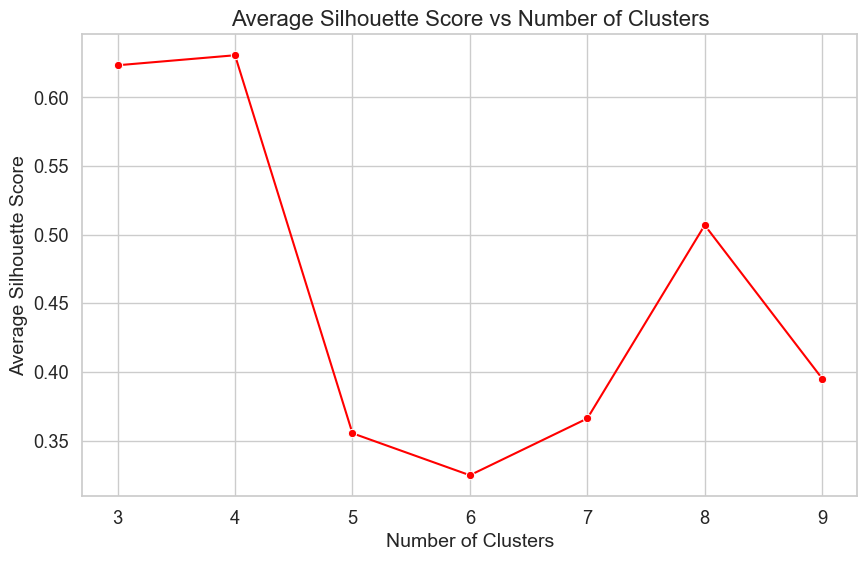

In [24]:
# Define variables
range_n_clusters = list(range(3,10))
sample_pca_results = pca_results_combined[['PC1', 'PC2', 'PC3']].sample(25000, random_state=seed_number)

# Standardize the sample data
scaler = StandardScaler()
sample_pca_results = scaler.fit_transform(sample_pca_results)

# Initialize list to store silhouette scores
silhouette_scores = []
cluster_labels_list = []

# Loop through each number of clusters
for n_clusters in range_n_clusters:
    clusterer = MiniBatchKMeans(n_clusters=n_clusters, random_state=seed_number, batch_size=3072)
    cluster_labels = clusterer.fit_predict(sample_pca_results)

    silhouette_avg = silhouette_score(sample_pca_results, cluster_labels)
    silhouette_scores.append(silhouette_avg)  # Store the average silhouette score
    cluster_labels_list.append(cluster_labels)  # Store cluster labels for each n_clusters
    print(f"For n_clusters = {n_clusters}, the average silhouette_score is : {silhouette_avg:.4f}")

# Create a line plot for silhouette scores
plt.figure(figsize=(10, 6))
sns.lineplot(x=range_n_clusters, y=silhouette_scores, marker='o', color='red')

# Add titles and labels, export the image
plt.title('Average Silhouette Score vs Number of Clusters', fontsize=16)
plt.xlabel('Number of Clusters', fontsize=14)
plt.ylabel('Average Silhouette Score', fontsize=14)
plt.xticks(range_n_clusters)  # Set x-ticks to the number of clusters
plt.grid(True)
plt.savefig('C:/Users/monaliza/PycharmProjects/paper-multiscalar-foreground-network/0_data-visualization/3-om-elbow.png.png', format='png', dpi=300, bbox_inches='tight')
plt.show()

#### Clustering using Clara method (K-medoids)

In [25]:
# Create a copy of the original PCA results DataFrame
combined_pca_clustering_results = pca_results_combined.copy()

# Extract the first three principal components
combined_pca_clustering_results_filtered = combined_pca_clustering_results[['PC1', 'PC2', 'PC3']]

# Standardize the PCA components before clustering
scaler = StandardScaler()
combined_pca_clustering_results_filtered_scaled = scaler.fit_transform(combined_pca_clustering_results_filtered)

# Initialize the CLARA clustering model
clara_model = CLARA(n_clusters=4, metric='euclidean', n_sampling=10000, random_state=seed_number)

# Fit the model on the scaled PCA data
clara_model.fit(combined_pca_clustering_results_filtered_scaled)

# Retrieve cluster labels
labels = clara_model.labels_

# Retrieve cluster centers (medoids)
medoids = clara_model.cluster_centers_

# Add cluster labels to the original (unscaled) DataFrame
combined_pca_clustering_results['cluster_4'] = labels

# Display the first few rows of the result
combined_pca_clustering_results.head()

,city,fid,geometry,id,uv,abw500,abw1k,abw1500,abw2k,abw2500,...,arw2500ab,arw3kab,arw3500ab,arw4kab,arw4500ab,arw5kab,PC1,PC2,PC3,cluster_4
0,Gothenburg,1,"LINESTRING (1342159.842 7883580.812, 1342181.1...",1.0,148923_2613675388,3030.0,32290.5,72624.50,150848.50,245350.50,...,2.014831e+09,3.475437e+09,5.418215e+09,8.256957e+09,1.209819e+10,1.693630e+10,-0.475835,0.151286,-0.216617,0
1,Gothenburg,2,"LINESTRING (1342169.171 7883499.833, 1342181.1...",2.0,148923_2613675332,2869.0,31370.5,70602.50,146965.00,239544.00,...,1.990852e+09,3.455119e+09,5.393152e+09,8.207814e+09,1.205340e+10,1.688524e+10,-0.506122,0.125654,-0.222108,0
2,Gothenburg,3,"LINESTRING (1345950.739 7898301.149, 1345956.5...",3.0,162381_5706052174,1876.5,28714.5,93314.75,222719.50,428228.00,...,1.260040e+09,3.138001e+09,5.988620e+09,9.828824e+09,1.471329e+10,2.146860e+10,0.397994,-0.479099,-0.215926,0
3,Gothenburg,4,"LINESTRING (1345947.221 7898257.083, 1345950.7...",4.0,162381_270591673,1969.0,28880.0,94004.75,224205.00,431086.00,...,1.299625e+09,3.194895e+09,6.064203e+09,9.889367e+09,1.482488e+10,2.160874e+10,0.411631,-0.469971,-0.209696,0
4,Gothenburg,5,"LINESTRING (1345954.679 7898196.095, 1345949.8...",5.0,162382_360626365,2077.0,8184.5,17485.00,26618.75,37945.25,...,1.401343e+09,3.263055e+09,6.132714e+09,1.005165e+10,1.505325e+10,2.195940e+10,-1.300893,-0.155796,0.000312,0


#### Filter Data

In [28]:
# Function "filter gdf":
got_clustering_results = filter_gdf(combined_pca_clustering_results, 'Gothenburg')
ver_clustering_results = filter_gdf(combined_pca_clustering_results, 'Versilia')
nic_clustering_results = filter_gdf(combined_pca_clustering_results, 'Nice')
lil_clustering_results = filter_gdf(combined_pca_clustering_results, 'Lille')
vie_clustering_results = filter_gdf(combined_pca_clustering_results, 'Vienna')

#### Reproject Data

In [29]:
# Function "reproject_crs":
got_clustering_results_original_projection = reproject_crs(got_clustering_results, 'EPSG:3006')
ver_clustering_results_original_projection = reproject_crs(ver_clustering_results, 'EPSG:3003')
nic_clustering_results_original_projection = reproject_crs(nic_clustering_results, 'EPSG:2154')
lil_clustering_results_original_projection = reproject_crs(lil_clustering_results, 'EPSG:2154')
vie_clustering_results_original_projection = reproject_crs(vie_clustering_results, 'EPSG:31256')

#### Export Data

In [30]:
# Function "export":
export(combined_pca_clustering_results, '3_om_cluster_results_nms_combined_cities_EPSG3857', 's8_paper_multiscalar_foreground_network', engine)
export(got_clustering_results_original_projection, '3_om_cluster_results_nms_got_EPSG3006', 's8_paper_multiscalar_foreground_network', engine)
export(ver_clustering_results_original_projection, '3_om_cluster_results_nms_ver_EPSG3003', 's8_paper_multiscalar_foreground_network', engine)
export(nic_clustering_results_original_projection , '3_om_cluster_results_nms_nic_EPSG2154', 's8_paper_multiscalar_foreground_network', engine)
export(lil_clustering_results_original_projection , '3_om_cluster_results_nms_lil_EPSG2154', 's8_paper_multiscalar_foreground_network', engine)
export(vie_clustering_results_original_projection , '3_om_cluster_results_nms_vie_EPSG2154', 's8_paper_multiscalar_foreground_network', engine)

#### Visualize: group the number by zscores, plot the data

In [31]:
# Copy the original DataFrame
combined_pca_clustering_zscore_results = combined_pca_clustering_results.copy()

# Define the prefixes for z-score scaling
prefixes = ['abw']

# Initialize the scaler
scaler = StandardScaler()

# Iterate through each prefix to scale and add z-score columns
for prefix in prefixes:
    # Filter columns starting with the current prefix
    selected_columns = [col for col in combined_pca_clustering_results.columns if col.startswith(prefix)]

    # Fit and transform the selected columns
    zscore_values = scaler.fit_transform(combined_pca_clustering_results[selected_columns])

    # Create a DataFrame with the scaled values
    zscore_df = pd.DataFrame(zscore_values, columns=[f'zscore_{col}' for col in selected_columns], index=combined_pca_clustering_results.index)

    # Add the z-score columns back to the original DataFrame
    combined_pca_clustering_results = pd.concat([combined_pca_clustering_results, zscore_df], axis=1)

# Display the updated DataFrame with z-scores
combined_pca_clustering_results.head()

,city,fid,geometry,id,uv,abw500,abw1k,abw1500,abw2k,abw2500,...,zscore_abw500,zscore_abw1k,zscore_abw1500,zscore_abw2k,zscore_abw2500,zscore_abw3k,zscore_abw3500,zscore_abw4k,zscore_abw4500,zscore_abw5k
0,Gothenburg,1,"LINESTRING (1342159.842 7883580.812, 1342181.1...",1.0,148923_2613675388,3030.0,32290.5,72624.50,150848.50,245350.50,...,0.324820,0.799963,0.461161,0.392699,0.293455,0.186899,0.106452,0.044423,-0.007135,-0.044036
1,Gothenburg,2,"LINESTRING (1342169.171 7883499.833, 1342181.1...",2.0,148923_2613675332,2869.0,31370.5,70602.50,146965.00,239544.00,...,0.283101,0.765273,0.437614,0.373363,0.278560,0.175293,0.097121,0.037054,-0.013105,-0.048950
2,Gothenburg,3,"LINESTRING (1345950.739 7898301.149, 1345956.5...",3.0,162381_5706052174,1876.5,28714.5,93314.75,222719.50,428228.00,...,0.025918,0.665123,0.702103,0.750548,0.762596,0.827699,0.869835,0.885198,0.814223,0.714213
3,Gothenburg,4,"LINESTRING (1345947.221 7898257.083, 1345950.7...",4.0,162381_270591673,1969.0,28880.0,94004.75,224205.00,431086.00,...,0.049887,0.671364,0.710138,0.757944,0.769927,0.834303,0.875622,0.890186,0.818761,0.718146
4,Gothenburg,5,"LINESTRING (1345954.679 7898196.095, 1345949.8...",5.0,162382_360626365,2077.0,8184.5,17485.00,26618.75,37945.25,...,0.077873,-0.108997,-0.180950,-0.225846,-0.238607,-0.242204,-0.241400,-0.241787,-0.238520,-0.235497


# Define custom colors for each cluster (by type)
cluster_palette = {
    'Background type': '#cfe5e3',
    'Local type': '#338687',
    'Neighborhood type': '#cd993f',
    'City type': '#85563F'
}

# Define a mapping from numeric cluster labels to descriptive names
cluster_label_map = {
    0: 'Background type',
    1: 'Local type',
    2: 'Neighborhood type',
    3: 'City type'
}

# Filter the columns that start with 'zscore_abw'
zscore_columns = [col for col in combined_pca_clustering_results.columns if col.startswith('zscore_abw')]

# Map numeric clusters to descriptive labels
combined_pca_clustering_results['cluster_4_label'] = combined_pca_clustering_results['cluster_4'].map(cluster_label_map)

# Melt the DataFrame for plotting
melted_zscore = combined_pca_clustering_results.melt(
    id_vars=['cluster_4_label'],  # Use labeled cluster column
    value_vars=zscore_columns,
    var_name='zscore variable',
    value_name='value'
)

# Set the style of the visualization
sns.set(style='whitegrid')

# Create the line plot
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=melted_zscore,
    x='zscore variable',
    y='value',
    hue='cluster_4_label',  # Use the labeled cluster column for the legend
    marker='o',
    palette=cluster_palette
)

# Customize the plot
plt.title('Cluster Analysis', fontsize=18)
plt.xlabel('Radius (km)', fontsize=14)
plt.ylabel('Betweenness', fontsize=14)
plt.xticks(rotation=45)
plt.legend(title='Cluster Type', fontsize=12)
plt.grid(True)

# Show and save the plot
plt.tight_layout()
plt.savefig(
    'C:/Users/monaliza/PycharmProjects/paper-multiscalar-foreground-network/0_data-visualization/4_om_cluster_lineplot_combined',
    format='png', dpi=300, bbox_inches='tight'
)
plt.show()
#### Visualize: cluster combined cities

In [ ]:
# Define custom colors for each cluster (by type)
cluster_palette = {
    'Background type': '#cfe5e3',
    'Local type': '#338687',
    'Neighborhood type': '#cd993f',
    'City type': '#85563F'
}

# Define a mapping from numeric cluster labels to descriptive names
cluster_label_map = {
    0: 'Background type',
    1: 'Local type',
    2: 'Neighborhood type',
    3: 'City type'
}

# Filter the columns that start with 'zscore_abw'
zscore_columns = [col for col in combined_pca_clustering_results.columns if col.startswith('zscore_abw')]

# Map numeric clusters to descriptive labels
combined_pca_clustering_results['cluster_4_label'] = combined_pca_clustering_results['cluster_4'].map(cluster_label_map)

# Melt the DataFrame for plotting
melted_zscore = combined_pca_clustering_results.melt(
    id_vars=['cluster_4_label'],  # Use labeled cluster column
    value_vars=zscore_columns,
    var_name='zscore variable',
    value_name='value'
)

# Set the style of the visualization
sns.set(style='whitegrid')

# Create the line plot
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=melted_zscore,
    x='zscore variable',
    y='value',
    hue='cluster_4_label',  # Use the labeled cluster column for the legend
    marker='o',
    palette=cluster_palette
)

# Customize the plot
plt.title('Cluster Analysis Original Method - Combined Cities', fontsize=18)
plt.xlabel('Radius (km)', fontsize=14)
plt.ylabel('Betweenness', fontsize=14)
plt.xticks(rotation=45)
plt.legend(title='Cluster Type', fontsize=12)
plt.grid(True)

# Show and save the plot
plt.tight_layout()
plt.savefig(
    'C:/Users/monaliza/PycharmProjects/paper-multiscalar-foreground-network/0_data-visualization/4_om_cluster_lineplot_combined.png',
    format='png', dpi=300, bbox_inches='tight'
)
plt.show()

#### Visualize: cluster by city

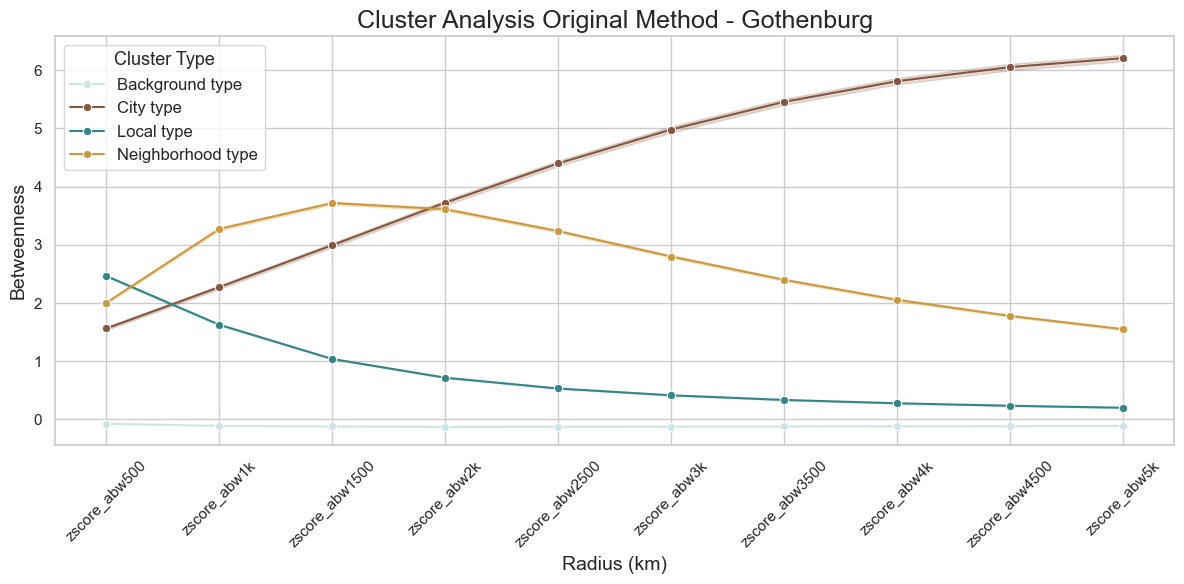

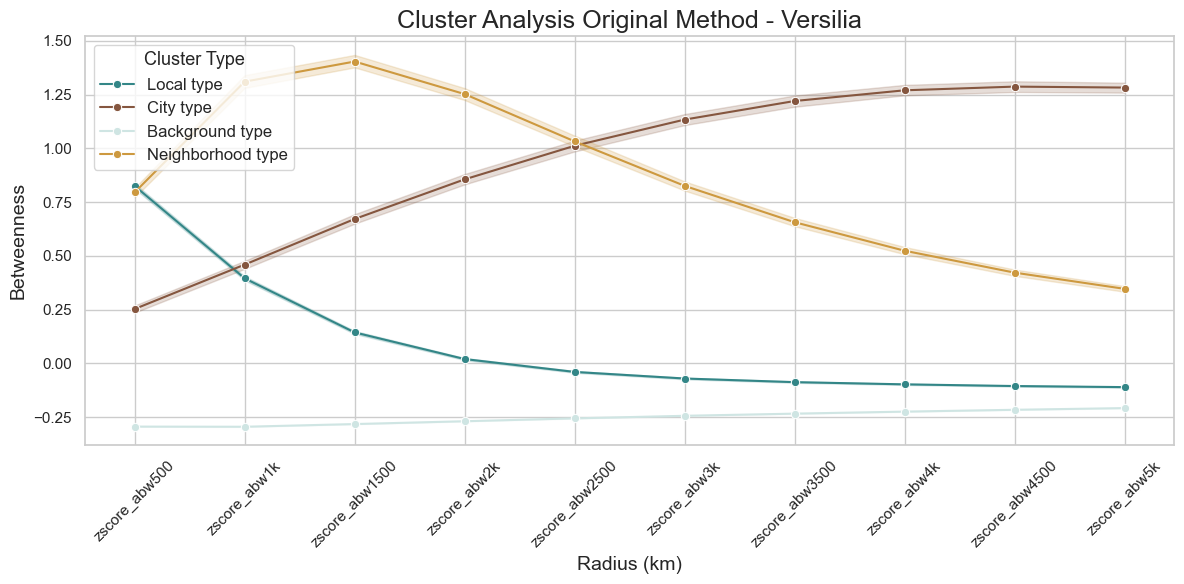

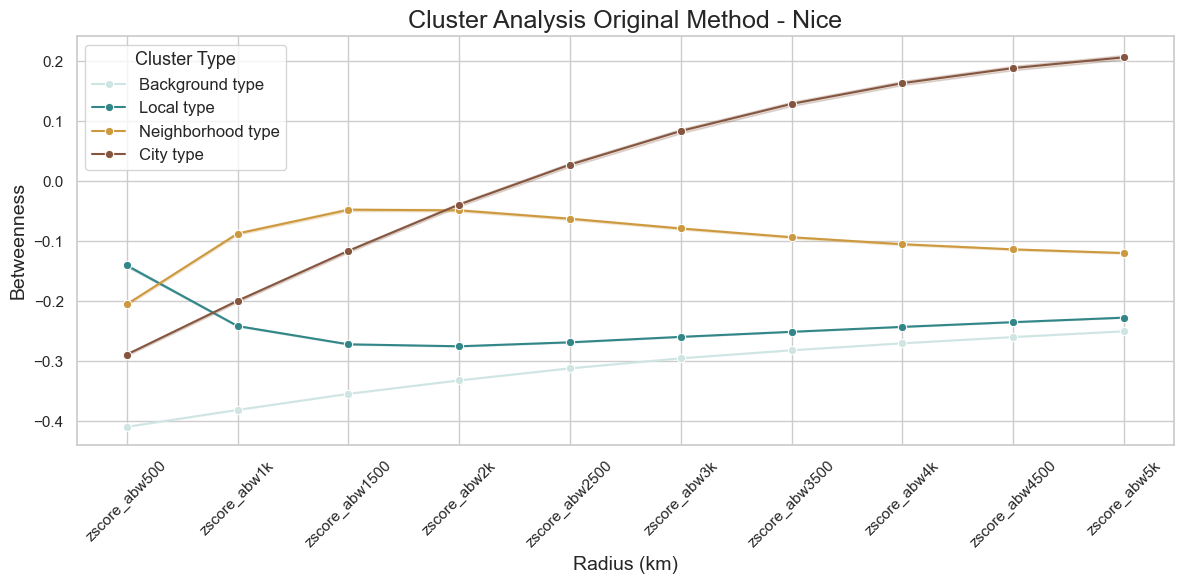

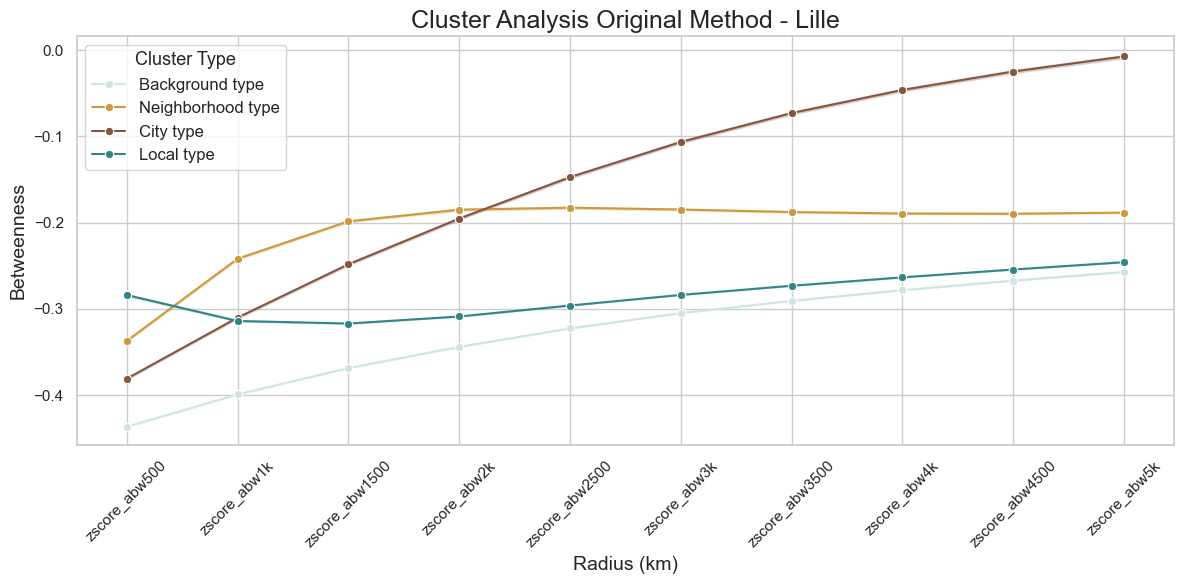

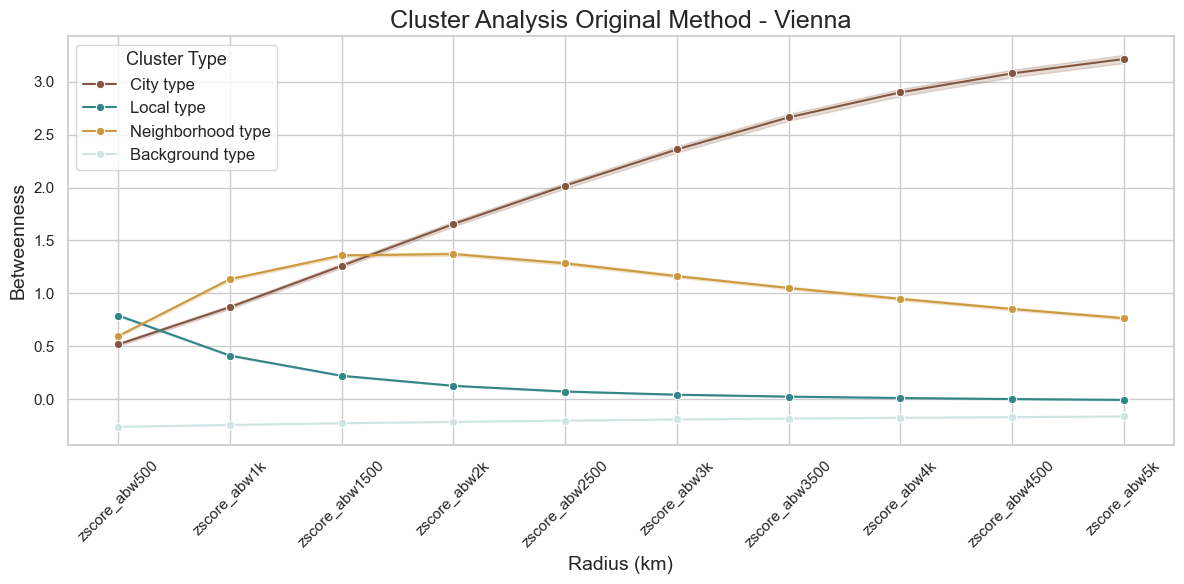

In [36]:
# Define custom colors for each cluster type (by label)
cluster_palette = {
    'Background type': '#cfe5e3',
    'Local type': '#338687',
    'Neighborhood type': '#cd993f',
    'City type': '#85563F'
}

# Map numeric cluster labels to descriptive names
cluster_label_map = {
    0: 'Background type',
    1: 'Local type',
    2: 'Neighborhood type',
    3: 'City type'
}

# Filter columns that start with 'zscore_abw'
norm_columns = [col for col in combined_pca_clustering_results.columns if col.startswith('zscore_abw')]

# Create a new column with descriptive cluster labels
combined_pca_clustering_results['cluster_4_label'] = combined_pca_clustering_results['cluster_4'].map(cluster_label_map)

# Loop through each city and create a separate plot
for city in combined_pca_clustering_results['city'].unique():
    city_data = combined_pca_clustering_results[combined_pca_clustering_results['city'] == city]

    # Melt the DataFrame for line plotting
    melted_no_scaling = city_data.melt(
        id_vars=['cluster_4_label'],  # Use descriptive labels
        value_vars=norm_columns,
        var_name='norm variable',
        value_name='value'
    )

    # Set the style
    sns.set(style='whitegrid')

    # Create the line plot
    plt.figure(figsize=(12, 6))
    sns.lineplot(
        data=melted_no_scaling,
        x='norm variable',
        y='value',
        hue='cluster_4_label',  # Descriptive cluster labels
        marker='o',
        palette=cluster_palette
    )

    # Customize the plot
    plt.title(f'Cluster Analysis Original Method - {city}', fontsize=18)
    plt.xlabel('Radius (km)', fontsize=14)
    plt.ylabel('Betweenness', fontsize=14)
    plt.xticks(rotation=45)
    plt.legend(
        title='Cluster Type',
        fontsize=12,
        title_fontsize=13,
        loc='upper left'  # Legend position
    )
    plt.grid(True)

    # Save and show the plot
    plt.tight_layout()
    plt.savefig(
        f'C:/Users/monaliza/PycharmProjects/paper-multiscalar-foreground-network/0_data-visualization/4_om_cluster_lineplot_{city}.png',
        format='png', dpi=300, bbox_inches='tight'
    )
    plt.show()

#### Export Data

In [38]:
# Function "export":
export(combined_pca_clustering_results, '4_om_zscores_results_nms_combined_cities', 's8_paper_multiscalar_foreground_network', engine)